In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 项目根目录
ROOT = Path.cwd()

if ROOT.name == "pipeline":
    ROOT = ROOT.parent

# 读取同学的原始仓位
weights_path = ROOT / "results/signals/ensemble_weights_history.csv"

raw_weights = pd.read_csv(
    weights_path,
    index_col=0,
    parse_dates=True
)

# 只提取真正交易的6只ETF
ETFS = ["TQQQ", "UVXY", "TECL", "SPXL", "TECS", "BSV"]

raw_weights = raw_weights[ETFS]

# 检查数据
print("数据形状：", raw_weights.shape)
print("开始日期：", raw_weights.index.min())
print("结束日期：", raw_weights.index.max())
print("是否存在缺失值：", raw_weights.isna().any().any())
print("每天仓位总和是否为1：",
      np.allclose(raw_weights.sum(axis=1), 1.0))

display(raw_weights.head())

数据形状： (3570, 6)
开始日期： 2012-08-01 00:00:00
结束日期： 2026-10-13 00:00:00
是否存在缺失值： False
每天仓位总和是否为1： True


,TQQQ,UVXY,TECL,SPXL,TECS,BSV
2012-08-01,1.000000,0.000000,0.0,0.0,0.0,0.0
2012-08-02,1.000000,0.000000,0.0,0.0,0.0,0.0
2012-08-03,1.000000,0.000000,0.0,0.0,0.0,0.0
2012-08-06,0.916667,0.083333,0.0,0.0,0.0,0.0
2012-08-07,0.750000,0.250000,0.0,0.0,0.0,0.0


In [23]:
# Step 2: 读取ETF历史价格数据

price_path = ROOT / "data/raw/etf_daily.csv"

prices_raw = pd.read_csv(price_path)

print("数据维度：", prices_raw.shape)

print("前5行：")
display(prices_raw.head())

print("所有列名：")
print(prices_raw.columns.tolist())

数据维度： (3921, 67)
前5行：


,Price,Adj Close,Adj Close.1,Adj Close.2,Adj Close.3,Adj Close.4,Adj Close.5,Adj Close.6,Adj Close.7,Adj Close.8,...,Volume.1,Volume.2,Volume.3,Volume.4,Volume.5,Volume.6,Volume.7,Volume.8,Volume.9,Volume.10
0,Ticker,BSV,ES3.SI,QQQ,SGD=X,SPXL,SPY,SQQQ,TECL,TECS,...,ES3.SI,QQQ,SGD=X,SPXL,SPY,SQQQ,TECL,TECS,TQQQ,UVXY
1,Date,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2011-10-03,59.514373779296875,1.6502271890640259,44.95072555541992,1.305799961090088,3.1786670684814453,84.6581039428711,3459891.25,0.646538257598877,20966566.0,...,568000.0,99149500.0,0.0,61560000.0,365136800.0,29.0,125252000.0,2.0,410649600.0,NaN
3,2011-10-04,59.39738082885742,1.6071243286132812,45.87364196777344,1.3158999681472778,3.3967151641845703,86.51405334472656,3241016.5,0.6894288063049316,19577774.0,...,882000.0,137013700.0,0.0,105518400.0,459177500.0,32.0,160000000.0,2.0,689280000.0,0.0
4,2011-10-05,59.353519439697266,1.6009666919708252,47.05146789550781,1.307800054550171,3.5913732051849365,88.11588287353516,2996889.25,0.7407159805297852,18130060.0,...,975000.0,108825700.0,0.0,71014800.0,284108000.0,27.0,159052000.0,2.0,520569600.0,0.0


所有列名：
['Price', 'Adj Close', 'Adj Close.1', 'Adj Close.2', 'Adj Close.3', 'Adj Close.4', 'Adj Close.5', 'Adj Close.6', 'Adj Close.7', 'Adj Close.8', 'Adj Close.9', 'Adj Close.10', 'Close', 'Close.1', 'Close.2', 'Close.3', 'Close.4', 'Close.5', 'Close.6', 'Close.7', 'Close.8', 'Close.9', 'Close.10', 'High', 'High.1', 'High.2', 'High.3', 'High.4', 'High.5', 'High.6', 'High.7', 'High.8', 'High.9', 'High.10', 'Low', 'Low.1', 'Low.2', 'Low.3', 'Low.4', 'Low.5', 'Low.6', 'Low.7', 'Low.8', 'Low.9', 'Low.10', 'Open', 'Open.1', 'Open.2', 'Open.3', 'Open.4', 'Open.5', 'Open.6', 'Open.7', 'Open.8', 'Open.9', 'Open.10', 'Volume', 'Volume.1', 'Volume.2', 'Volume.3', 'Volume.4', 'Volume.5', 'Volume.6', 'Volume.7', 'Volume.8', 'Volume.9', 'Volume.10']


In [24]:
# Step 3: 正确读取多层表头的ETF数据

prices = pd.read_csv(
    price_path,
    header=[0, 1],
    index_col=0,
    parse_dates=True
)

# 提取调整后收盘价
adj_close = prices["Adj Close"][ETFS].copy()

# 按日期排序
adj_close = adj_close.sort_index()

# 确保价格都是数字
adj_close = adj_close.apply(
    pd.to_numeric,
    errors="coerce"
)

# 计算每日简单收益率
daily_returns = adj_close.pct_change(fill_method=None)

# 检查数据
print("价格数据形状：", adj_close.shape)

print("开始日期：", adj_close.index.min())
print("结束日期：", adj_close.index.max())

print("\n各ETF缺失值数量：")
print(adj_close.isna().sum())

print("\n每日收益率前5行：")
display(daily_returns.head())

价格数据形状： (3919, 6)
开始日期： 2011-10-03 00:00:00
结束日期： 2026-10-14 00:00:00

各ETF缺失值数量：
Ticker
TQQQ    140
UVXY    141
TECL    140
SPXL    140
TECS    140
BSV     140
dtype: int64

每日收益率前5行：


Ticker,TQQQ,UVXY,TECL,SPXL,TECS,BSV
Date,,,,,,
2011-10-03,NaN,NaN,NaN,NaN,NaN,NaN
2011-10-04,0.060848,NaN,0.066339,0.068597,-0.066238,-0.001966
2011-10-05,0.076020,-0.118659,0.074391,0.057308,-0.073947,-0.000738
2011-10-06,0.051382,-0.040688,0.053309,0.057773,-0.051532,-0.001972
2011-10-07,-0.020619,0.014483,-0.017161,-0.025819,0.016642,0.001358


In [25]:
# Step 4.1: 检查仓位日期是否都有完整的ETF价格

# 与同学的原始仓位日期对齐
aligned_prices = adj_close.reindex(raw_weights.index)

# 统计缺失值
print("与仓位日期对齐后的价格缺失值：")
print(aligned_prices.isna().sum())

# 找出存在缺失值的日期
missing_dates = aligned_prices[
    aligned_prices.isna().any(axis=1)
]

print("\n存在价格缺失的日期数量：", len(missing_dates))

display(missing_dates.head(10))

# 检查最后几天的数据
print("\n最近5天的价格：")
display(aligned_prices.tail())

与仓位日期对齐后的价格缺失值：
Ticker
TQQQ    0
UVXY    0
TECL    0
SPXL    0
TECS    0
BSV     0
dtype: int64

存在价格缺失的日期数量： 0


Ticker,TQQQ,UVXY,TECL,SPXL,TECS,BSV



最近5天的价格：


Ticker,TQQQ,UVXY,TECL,SPXL,TECS,BSV
2026-10-07,83.620003,16.190001,252.470001,296.910004,47.669998,76.360001
2026-10-08,80.230003,16.639999,238.720001,293.049988,50.169998,76.410004
2026-10-09,81.279999,16.320000,242.350006,297.970001,49.619999,76.379997
2026-10-12,79.610001,15.980000,233.130005,297.369995,51.380001,76.389999
2026-10-13,78.809998,15.940000,232.720001,297.420013,51.580002,76.370003


In [26]:
# Step 4.2: 计算每日原始组合的预计年化波动率

LOOKBACK = 60
TRADING_DAYS = 252

# 确保收益率日期按升序排列
daily_returns = daily_returns.sort_index()

# 只使用完整的6只ETF收益率
valid_returns = daily_returns[ETFS].dropna()

# 检查2012年8月1日之前是否有足够的历史数据
first_date = raw_weights.index.min()

history_before_start = valid_returns.loc[
    valid_returns.index < first_date
]

print("策略开始前的完整历史收益率天数：",
      len(history_before_start))

assert len(history_before_start) >= LOOKBACK, (
    "策略开始前不足60个完整交易日，请检查价格数据。"
)

portfolio_vol = pd.Series(
    index=raw_weights.index,
    dtype=float,
    name="Predicted_Volatility"
)

for date in raw_weights.index:

    # 1. 取截至当天最近60个交易日的收益率
    past_returns = valid_returns.loc[:date].tail(LOOKBACK)

    if len(past_returns) < LOOKBACK:
        continue

    # 2. 当天6只ETF的原始仓位
    w = raw_weights.loc[date, ETFS].to_numpy(dtype=float)

    # 3. 计算60日协方差矩阵
    cov_matrix = past_returns.cov().to_numpy()

    # 4. 计算组合年化波动率
    variance = w @ cov_matrix @ w

    portfolio_vol.loc[date] = np.sqrt(
        TRADING_DAYS * max(variance, 0)
    )

# 查看结果
print("\n预计年化波动率统计：")
display(portfolio_vol.describe())

print("\n前5天的预计年化波动率：")
display(portfolio_vol.head())

print("\n最近5天的预计年化波动率：")
display(portfolio_vol.tail())

print("\n无法计算波动率的天数：",
      portfolio_vol.isna().sum())

策略开始前的完整历史收益率天数： 199

预计年化波动率统计：


count    3570.000000
mean        0.449365
std         0.225973
min         0.010192
25%         0.301912
50%         0.418280
75%         0.549022
max         2.031443
Name: Predicted_Volatility, dtype: float64


前5天的预计年化波动率：


2012-08-01    0.591180
2012-08-02    0.572365
2012-08-03    0.584382
2012-08-06    0.440023
2012-08-07    0.280220
Name: Predicted_Volatility, dtype: float64


最近5天的预计年化波动率：


2026-10-07    0.346182
2026-10-08    0.552568
2026-10-09    0.552683
2026-10-12    0.544167
2026-10-13    0.535607
Name: Predicted_Volatility, dtype: float64


无法计算波动率的天数： 0


In [27]:
# Step 5: 根据各ETF的历史波动率调整原始仓位

LOOKBACK = 60
TRADING_DAYS = 252

adjusted_weights = pd.DataFrame(
    index=raw_weights.index,
    columns=ETFS,
    dtype=float
)

for date in raw_weights.index:

    # 1. 获取当天同学提供的原始仓位
    w_raw = raw_weights.loc[date, ETFS]

    # 2. 获取截至当天过去60个交易日的收益率
    past_returns = valid_returns.loc[:date].tail(LOOKBACK)

    # 3. 计算每只ETF的年化波动率
    asset_vol = past_returns.std() * np.sqrt(TRADING_DAYS)

    # 4. 根据原始仓位和波动率计算得分
    scores = w_raw / asset_vol

    # 5. 标准化，使全部仓位加起来等于100%
    w_final = scores / scores.sum()

    # 6. 保存最终仓位
    adjusted_weights.loc[date] = w_final

# 检查结果
print("所有日期仓位是否合计100%：")
print(np.allclose(adjusted_weights.sum(axis=1), 1.0))

print("\n是否存在负仓位：")
print((adjusted_weights < 0).any().any())

print("\n最近5天原始仓位：")
display(raw_weights.tail())

print("\n最近5天调整后的仓位：")
display(adjusted_weights.tail())

print("\n平均仓位对比：")
comparison = pd.DataFrame({
    "Original": raw_weights.mean(),
    "Adjusted": adjusted_weights.mean()
})

display(comparison)

所有日期仓位是否合计100%：
True

是否存在负仓位：
False

最近5天原始仓位：


,TQQQ,UVXY,TECL,SPXL,TECS,BSV
2026-10-07,0.75,0.25,0.0,0.0,0.0,0.0
2026-10-08,1.00,0.00,0.0,0.0,0.0,0.0
2026-10-09,1.00,0.00,0.0,0.0,0.0,0.0
2026-10-12,1.00,0.00,0.0,0.0,0.0,0.0
2026-10-13,1.00,0.00,0.0,0.0,0.0,0.0



最近5天调整后的仓位：


,TQQQ,UVXY,TECL,SPXL,TECS,BSV
2026-10-07,0.754127,0.245873,0.0,0.0,0.0,0.0
2026-10-08,1.000000,0.000000,0.0,0.0,0.0,0.0
2026-10-09,1.000000,0.000000,0.0,0.0,0.0,0.0
2026-10-12,1.000000,0.000000,0.0,0.0,0.0,0.0
2026-10-13,1.000000,0.000000,0.0,0.0,0.0,0.0



平均仓位对比：


,Original,Adjusted
TQQQ,0.735971,0.760521
UVXY,0.110611,0.071204
TECL,0.056964,0.051837
SPXL,0.003606,0.003147
TECS,0.055823,0.051284
BSV,0.037025,0.062008


In [28]:
# Step 6: 比较风险调整前后的预计年化波动率

adjusted_portfolio_vol = pd.Series(
    index=raw_weights.index,
    dtype=float,
    name="Adjusted_Volatility"
)

for date in raw_weights.index:

    # 获取过去60日的历史收益率
    past_returns = valid_returns.loc[:date].tail(LOOKBACK)

    # 计算协方差矩阵
    cov_matrix = past_returns.cov().to_numpy()

    # 获取调整后的ETF仓位
    w = adjusted_weights.loc[date, ETFS].to_numpy(dtype=float)

    # 计算调整后的组合波动率
    variance = w @ cov_matrix @ w

    adjusted_portfolio_vol.loc[date] = np.sqrt(
        TRADING_DAYS * max(variance, 0)
    )

# 比较原始组合和调整后组合
vol_comparison = pd.DataFrame({
    "Original_Vol": portfolio_vol,
    "Adjusted_Vol": adjusted_portfolio_vol
})

vol_comparison["Vol_Change"] = (
    vol_comparison["Adjusted_Vol"]
    - vol_comparison["Original_Vol"]
)

print("原始与调整后预计波动率统计：")
display(vol_comparison.describe())

print("\n风险降低的交易日比例：")
print(
    f"{(vol_comparison['Vol_Change'] < -1e-8).mean():.2%}"
)

print("\n风险上升的交易日比例：")
print(
    f"{(vol_comparison['Vol_Change'] > 1e-8).mean():.2%}"
)

print("\n最近5天风险对比：")
display(vol_comparison.tail())

原始与调整后预计波动率统计：


,Original_Vol,Adjusted_Vol,Vol_Change
count,3570.000000,3570.000000,3570.000000
mean,0.449365,0.428130,-0.021235
std,0.225973,0.232916,0.103783
min,0.010192,0.009066,-1.158844
25%,0.301912,0.293159,0.000000
50%,0.418280,0.406849,0.000000
75%,0.549022,0.530548,0.000000
max,2.031443,2.031443,0.233633



风险降低的交易日比例：
22.80%

风险上升的交易日比例：
23.64%

最近5天风险对比：


,Original_Vol,Adjusted_Vol,Vol_Change
2026-10-07,0.346182,0.349053,0.002871
2026-10-08,0.552568,0.552568,0.000000
2026-10-09,0.552683,0.552683,0.000000
2026-10-12,0.544167,0.544167,0.000000
2026-10-13,0.535607,0.535607,0.000000


In [29]:
# ============================================================
# Step 7: 使用小组原始回测函数计算两套策略的账户净值
# ============================================================

import ast
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. 读取同学的Notebook
# ------------------------------------------------------------

notebook_path = ROOT / "pipeline/09_parameter_ensemble.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)


# ------------------------------------------------------------
# 2. 定义小组原始回测函数使用的参数
# ------------------------------------------------------------

IS_START = "2012-08-01"

TICKS = ETFS

# 小组原始单边交易成本（单位：bps）
ONE_WAY_BPS = {
    "TQQQ": 1.0,
    "UVXY": 6.0,
    "TECL": 35.0,
    "SPXL": 16.0,
    "TECS": 15.0,
    "BSV": 1.0
}


# ------------------------------------------------------------
# 3. 提取同学的回测函数
# ------------------------------------------------------------

def load_function(notebook, function_name):

    for cell in notebook["cells"]:

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:

            if (
                isinstance(node, ast.FunctionDef)
                and node.name == function_name
            ):

                module = ast.Module(
                    body=[node],
                    type_ignores=[]
                )

                exec(
                    compile(module, "<notebook>", "exec"),
                    globals()
                )

                return

    raise ValueError(f"找不到函数：{function_name}")


load_function(nb, "backtest_weighted_portfolio")

print("回测函数加载成功！")


# ------------------------------------------------------------
# 4. 准备ETF开盘价和收盘价
# ------------------------------------------------------------

price_data = prices.sort_index()

# 原始收盘价
close_unadjusted = (
    price_data["Close"][ETFS]
    .astype(float)
)

# 调整后收盘价
close_adjusted = (
    price_data["Adj Close"][ETFS]
    .astype(float)
)

# 计算价格调整因子
adjustment_factor = (
    close_adjusted / close_unadjusted
)

# 将开盘价调整至相同价格口径
open_adjusted = (
    price_data["Open"][ETFS].astype(float)
    * adjustment_factor
)


# ------------------------------------------------------------
# 5. 对齐交易日期
# ------------------------------------------------------------

dates = raw_weights.index

O = open_adjusted.reindex(dates)
C = close_adjusted.reindex(dates)

assert O.notna().all().all(), "开盘价存在缺失值"
assert C.notna().all().all(), "收盘价存在缺失值"

assert raw_weights.index.equals(adjusted_weights.index), (
    "原始仓位和调整后仓位的日期不一致"
)

assert np.allclose(
    raw_weights.sum(axis=1), 1.0
), "原始仓位总和不是100%"

assert np.allclose(
    adjusted_weights.sum(axis=1), 1.0
), "调整后仓位总和不是100%"


# ------------------------------------------------------------
# 6. 回测原始投票策略
# ------------------------------------------------------------

original_equity, original_diag = backtest_weighted_portfolio(
    O,
    C,
    raw_weights,
    start=IS_START
)

print("原始策略回测完成！")


# ------------------------------------------------------------
# 7. 回测你的风险调整策略
# ------------------------------------------------------------

adjusted_equity, adjusted_diag = backtest_weighted_portfolio(
    O,
    C,
    adjusted_weights,
    start=IS_START
)

print("风险调整策略回测完成！")


# ------------------------------------------------------------
# 8. 检查结果
# ------------------------------------------------------------

equity_comparison = pd.DataFrame({
    "Original": original_equity,
    "Risk_Adjusted": adjusted_equity
})

print("\n========== 最近5天账户净值 ==========")
display(equity_comparison.tail())

print("\n========== 最终账户净值 ==========")

print(f"原始策略：{original_equity.iloc[-1]:.4f}")
print(f"风险调整：{adjusted_equity.iloc[-1]:.4f}")

print("\n========== 数据检查 ==========")

print("交易日数量：", len(equity_comparison))

print(
    "两组净值是否有缺失：",
    equity_comparison.isna().any().any()
)

print(
    "两组日期是否一致：",
    original_equity.index.equals(adjusted_equity.index)
)

回测函数加载成功！
原始策略回测完成！
风险调整策略回测完成！

========== 最近5天账户净值 ==========


,Original,Risk_Adjusted
2026-10-07,4236.216882,2924.666893
2026-10-08,4152.526380,2866.062226
2026-10-09,4169.682081,2878.322259
2026-10-12,4084.010803,2819.183566
2026-10-13,4042.970467,2790.853514



========== 最终账户净值 ==========
原始策略：4042.9705
风险调整：2790.8535

========== 数据检查 ==========
交易日数量： 3570
两组净值是否有缺失： False
两组日期是否一致： True


In [30]:
# ============================================================
# Step 8: 使用小组原始metrics函数计算策略绩效
# ============================================================

import ast
import json
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. 读取小组核心引擎
# ------------------------------------------------------------

engine_path = ROOT / "pipeline/00_engine.ipynb"

with open(engine_path, "r", encoding="utf-8") as f:
    engine_nb = json.load(f)


# ------------------------------------------------------------
# 2. 提取小组原始绩效函数
# ------------------------------------------------------------

def load_metrics_function(notebook):

    for cell in notebook["cells"]:

        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:

            if (
                isinstance(node, ast.FunctionDef)
                and node.name == "metrics"
            ):

                module = ast.Module(
                    body=[node],
                    type_ignores=[]
                )

                exec(
                    compile(module, "<engine>", "exec"),
                    globals()
                )

                return

    raise ValueError("找不到metrics函数")


load_metrics_function(engine_nb)

print("小组原始绩效函数加载成功！")


# ------------------------------------------------------------
# 3. 定义测试区间
# ------------------------------------------------------------

periods = {
    "IS": ("2012-08-01", "2019-12-31"),
    "OOS": ("2020-01-01", None),
    "OOS ex-2020": ("2021-01-01", None)
}


# ------------------------------------------------------------
# 4. 计算两套策略的绩效
# ------------------------------------------------------------

rows = []

for period, (start, end) in periods.items():

    for name, equity in [
        ("Original Ensemble", original_equity),
        ("Risk Adjusted", adjusted_equity)
    ]:

        result = metrics(
            equity,
            a=start,
            b=end
        )

        rows.append({
            "Strategy": name,
            "Period": period,
            **result
        })


# ------------------------------------------------------------
# 5. 汇总结果
# ------------------------------------------------------------

performance_comparison = pd.DataFrame(rows)

print("\n========== 风险调整前后绩效比较 ==========")

display(performance_comparison.round(4))


# ------------------------------------------------------------
# 6. 单独查看样本外结果
# ------------------------------------------------------------

oos_performance = performance_comparison[
    performance_comparison["Period"] == "OOS"
]

print("\n========== 样本外绩效 ==========")

display(oos_performance.round(4))


# ------------------------------------------------------------
# 7. 与同学之前保存的结果进行核对
# ------------------------------------------------------------

saved_metrics_path = (
    ROOT / "results/tables/ensemble_metrics.csv"
)

saved_metrics = pd.read_csv(saved_metrics_path)

saved_ensemble = saved_metrics[
    saved_metrics["Strategy"] == "Ensemble 6336"
]

print("\n========== 同学保存的原始策略绩效 ==========")

display(saved_ensemble.round(4))

小组原始绩效函数加载成功！

========== 风险调整前后绩效比较 ==========


,Strategy,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,Original Ensemble,IS,0.5164,0.4386,1.1676,1.7996,-0.6015,0.8585
1,Risk Adjusted,IS,0.5255,0.4081,1.2404,1.8616,-0.5278,0.9956
2,Original Ensemble,OOS,1.1504,0.5926,1.5872,2.5635,-0.4907,2.3444
3,Risk Adjusted,OOS,1.0196,0.5569,1.5428,2.4004,-0.4465,2.2836
4,Original Ensemble,OOS ex-2020,0.5951,0.5416,1.1329,1.7408,-0.4907,1.2127
5,Risk Adjusted,OOS ex-2020,0.6253,0.5348,1.1754,1.8151,-0.4465,1.4004



========== 样本外绩效 ==========


,Strategy,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
2,Original Ensemble,OOS,1.1504,0.5926,1.5872,2.5635,-0.4907,2.3444
3,Risk Adjusted,OOS,1.0196,0.5569,1.5428,2.4004,-0.4465,2.2836



========== 同学保存的原始策略绩效 ==========


,Strategy,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,Ensemble 6336,IS,0.516,0.439,1.168,1.800,-0.601,0.858
1,Ensemble 6336,OOS,1.150,0.593,1.587,2.563,-0.491,2.344
2,Ensemble 6336,OOS ex-2020,0.595,0.542,1.133,1.741,-0.491,1.213


In [31]:
# ============================================================
# Step 9: 不同风险调整强度 Alpha 的稳健性测试
# ============================================================

ALPHAS = [0, 0.5, 1, 1.5]

LOOKBACK = 60

alpha_results = []
alpha_weights = {}
alpha_equities = {}

# 预先计算每日每只ETF的历史年化波动率
asset_vol_history = pd.DataFrame(
    index=raw_weights.index,
    columns=ETFS,
    dtype=float
)

for date in raw_weights.index:

    past_returns = valid_returns.loc[:date].tail(LOOKBACK)

    asset_vol_history.loc[date] = (
        past_returns.std() * np.sqrt(252)
    ).reindex(ETFS).values

# 检查历史波动率
assert asset_vol_history.notna().all().all()
assert (asset_vol_history > 0).all().all()

# 分别测试不同Alpha
for alpha in ALPHAS:

    # 1. 根据Alpha计算风险调整得分
    scores = raw_weights.div(
        asset_vol_history ** alpha
    )

    # 2. 标准化仓位
    weights = scores.div(
        scores.sum(axis=1),
        axis=0
    )

    # 3. 检查仓位
    assert np.allclose(weights.sum(axis=1), 1.0)
    assert (weights >= 0).all().all()

    # 4. 保存仓位
    alpha_weights[alpha] = weights

    # 5. 使用同学的回测函数
    equity, diag = backtest_weighted_portfolio(
        O,
        C,
        weights,
        start=IS_START
    )

    alpha_equities[alpha] = equity

    # 6. 分别计算三个区间的绩效
    for period, (start, end) in periods.items():

        result = metrics(
            equity,
            a=start,
            b=end
        )

        alpha_results.append({
            "Alpha": alpha,
            "Period": period,
            **result
        })

# 7. 整理结果
alpha_comparison = pd.DataFrame(alpha_results)

print("========== 不同Alpha的绩效 ==========")

display(alpha_comparison.round(4))


# 8. 单独查看样本内表现
print("\n========== 样本内 IS ==========")

display(
    alpha_comparison[
        alpha_comparison["Period"] == "IS"
    ].round(4)
)


# 9. 单独查看样本外表现
print("\n========== 样本外 OOS ==========")

display(
    alpha_comparison[
        alpha_comparison["Period"] == "OOS"
    ].round(4)
)


# 10. 查看不含2020年的结果
print("\n========== OOS ex-2020 ==========")

display(
    alpha_comparison[
        alpha_comparison["Period"] == "OOS ex-2020"
    ].round(4)
)

========== 不同Alpha的绩效 ==========


,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,0.0,IS,0.5164,0.4386,1.1676,1.7996,-0.6015,0.8585
1,0.0,OOS,1.1504,0.5926,1.5872,2.5635,-0.4907,2.3444
2,0.0,OOS ex-2020,0.5951,0.5416,1.1329,1.7408,-0.4907,1.2127
3,0.5,IS,0.5320,0.4200,1.2261,1.8716,-0.5581,0.9531
4,0.5,OOS,1.0759,0.5650,1.5772,2.4743,-0.4542,2.3687
5,0.5,OOS ex-2020,0.6160,0.5346,1.1649,1.7969,-0.4542,1.3561
6,1.0,IS,0.5255,0.4081,1.2404,1.8616,-0.5278,0.9956
7,1.0,OOS,1.0196,0.5569,1.5428,2.4004,-0.4465,2.2836
8,1.0,OOS ex-2020,0.6253,0.5348,1.1754,1.8151,-0.4465,1.4004
9,1.5,IS,0.5140,0.4011,1.2372,1.8264,-0.5259,0.9774



========== 样本内 IS ==========


,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,0.0,IS,0.5164,0.4386,1.1676,1.7996,-0.6015,0.8585
3,0.5,IS,0.5320,0.4200,1.2261,1.8716,-0.5581,0.9531
6,1.0,IS,0.5255,0.4081,1.2404,1.8616,-0.5278,0.9956
9,1.5,IS,0.5140,0.4011,1.2372,1.8264,-0.5259,0.9774



========== 样本外 OOS ==========


,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
1,0.0,OOS,1.1504,0.5926,1.5872,2.5635,-0.4907,2.3444
4,0.5,OOS,1.0759,0.5650,1.5772,2.4743,-0.4542,2.3687
7,1.0,OOS,1.0196,0.5569,1.5428,2.4004,-0.4465,2.2836
10,1.5,OOS,0.9980,0.5549,1.5272,2.3639,-0.4457,2.2390



========== OOS ex-2020 ==========


,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
2,0.0,OOS ex-2020,0.5951,0.5416,1.1329,1.7408,-0.4907,1.2127
5,0.5,OOS ex-2020,0.6160,0.5346,1.1649,1.7969,-0.4542,1.3561
8,1.0,OOS ex-2020,0.6253,0.5348,1.1754,1.8151,-0.4465,1.4004
11,1.5,OOS ex-2020,0.6331,0.5367,1.1822,1.8240,-0.4457,1.4204


In [32]:
# ============================================================
# Step 10.1: 保存风险调整策略的研究结果
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. 创建输出目录
# ------------------------------------------------------------

TABLE_DIR = ROOT / "results" / "tables"
SIGNAL_DIR = ROOT / "results" / "signals"
FIGURE_DIR = ROOT / "results" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
SIGNAL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. 确认采用 Alpha = 1
# ------------------------------------------------------------

SELECTED_ALPHA = 1.0

final_weights = alpha_weights[SELECTED_ALPHA].copy()
final_equity = alpha_equities[SELECTED_ALPHA].copy()

# 检查仓位
assert final_weights.index.equals(raw_weights.index)

assert np.allclose(
    final_weights.sum(axis=1),
    1.0
), "存在仓位总和不等于100%的日期"

assert (final_weights >= 0).all().all(), "存在负仓位"

assert final_weights.notna().all().all(), "存在缺失仓位"


# ------------------------------------------------------------
# 3. 保存每日风险调整仓位
# ------------------------------------------------------------

weights_output = (
    SIGNAL_DIR / "risk_adjusted_weights.csv"
)

final_weights.to_csv(
    weights_output,
    index_label="Date"
)

print("已保存每日调整后仓位：")
print(weights_output)


# ------------------------------------------------------------
# 4. 保存主要方案的绩效比较
# ------------------------------------------------------------

main_performance = performance_comparison.copy()

performance_output = (
    TABLE_DIR / "risk_performance.csv"
)

main_performance.to_csv(
    performance_output,
    index=False
)

print("\n已保存主要策略绩效：")
print(performance_output)


# ------------------------------------------------------------
# 5. 保存 Alpha 稳健性测试
# ------------------------------------------------------------

robustness_output = (
    TABLE_DIR / "risk_alpha_robustness.csv"
)

alpha_comparison.to_csv(
    robustness_output,
    index=False
)

print("\n已保存Alpha稳健性测试：")
print(robustness_output)


# ------------------------------------------------------------
# 6. 保存原始与风险调整策略的每日净值
# ------------------------------------------------------------

equity_output = pd.DataFrame({
    "Original": original_equity,
    "Risk_Adjusted": final_equity
})

equity_file = (
    TABLE_DIR / "risk_equity_history.csv"
)

equity_output.to_csv(
    equity_file,
    index_label="Date"
)

print("\n已保存每日净值：")
print(equity_file)


# ------------------------------------------------------------
# 7. 显示输出文件及大小
# ------------------------------------------------------------

print("\n========== 输出文件检查 ==========")

files = [
    weights_output,
    performance_output,
    robustness_output,
    equity_file
]

for file in files:

    print(
        f"{file.name}: "
        f"{file.stat().st_size / 1024:.2f} KB"
    )


# ------------------------------------------------------------
# 8. 显示最新调整仓位
# ------------------------------------------------------------

print("\n========== 最新风险调整仓位 ==========")

display(
    final_weights.tail(1).T.rename(
        columns={
            final_weights.index[-1]: "Weight"
        }
    )
)

已保存每日调整后仓位：
/Users/zhangjiaxin/Desktop/fe5209_vol_rotation/results/signals/risk_adjusted_weights.csv

已保存主要策略绩效：
/Users/zhangjiaxin/Desktop/fe5209_vol_rotation/results/tables/risk_performance.csv

已保存Alpha稳健性测试：
/Users/zhangjiaxin/Desktop/fe5209_vol_rotation/results/tables/risk_alpha_robustness.csv

已保存每日净值：
/Users/zhangjiaxin/Desktop/fe5209_vol_rotation/results/tables/risk_equity_history.csv

========== 输出文件检查 ==========
risk_adjusted_weights.csv: 178.58 KB
risk_performance.csv: 0.84 KB
risk_alpha_robustness.csv: 1.50 KB
risk_equity_history.csv: 166.89 KB

========== 最新风险调整仓位 ==========


,Weight
TQQQ,1.0
UVXY,0.0
TECL,0.0
SPXL,0.0
TECS,0.0
BSV,0.0


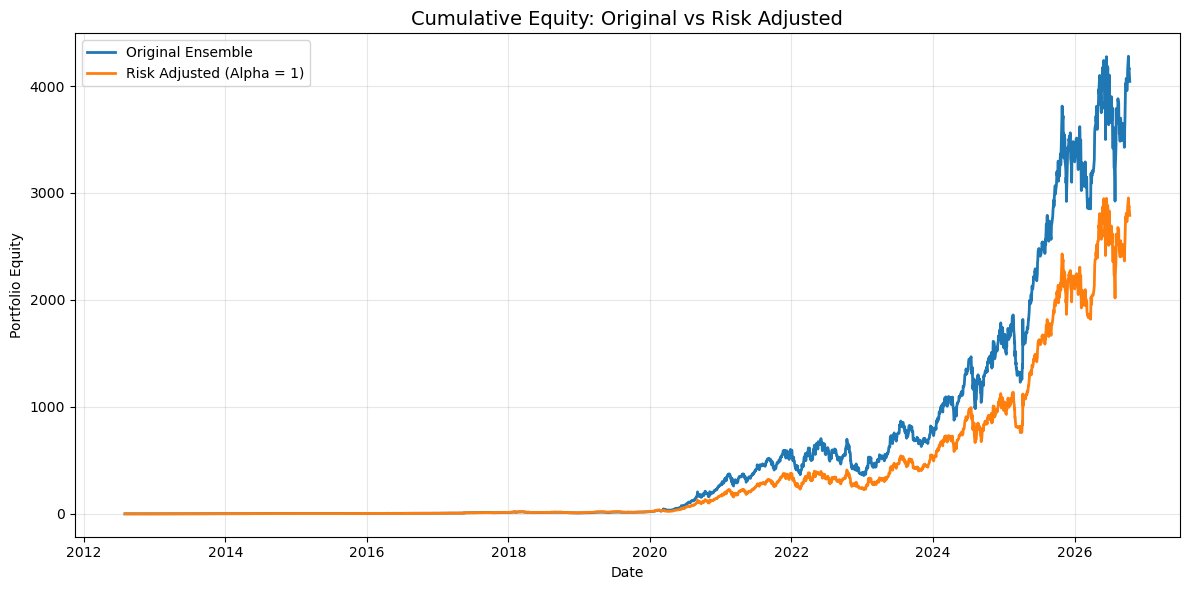

In [33]:
# ============================================================
# Step 10.2: 原始策略与风险调整策略累计净值对比
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# 原始投票策略
plt.plot(
    original_equity.index,
    original_equity.values,
    label="Original Ensemble",
    linewidth=2
)

# 风险调整策略
plt.plot(
    final_equity.index,
    final_equity.values,
    label="Risk Adjusted (Alpha = 1)",
    linewidth=2
)

plt.title(
    "Cumulative Equity: Original vs Risk Adjusted",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Portfolio Equity")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "risk_equity_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

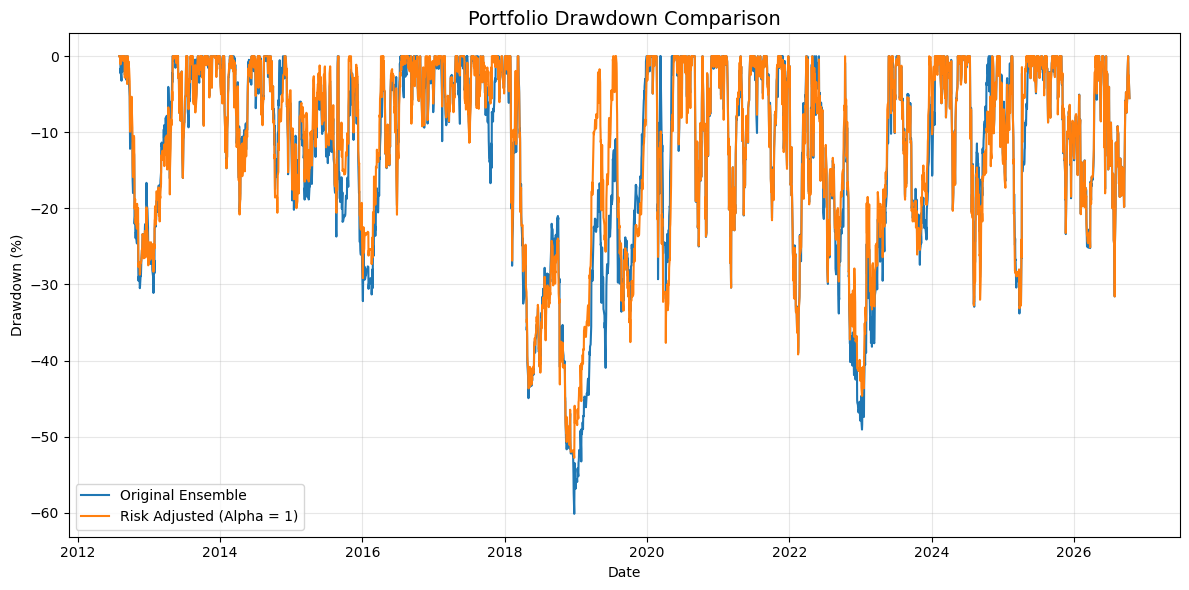

Full-period maximum drawdown:
Original: -60.15%
Risk Adjusted: -52.78%


In [34]:
# ============================================================
# Step 10.3: 最大回撤曲线对比
# ============================================================

# 计算每日回撤
original_drawdown = (
    original_equity / original_equity.cummax() - 1
)

adjusted_drawdown = (
    final_equity / final_equity.cummax() - 1
)

plt.figure(figsize=(12, 6))

plt.plot(
    original_drawdown.index,
    original_drawdown.values * 100,
    label="Original Ensemble",
    linewidth=1.5
)

plt.plot(
    adjusted_drawdown.index,
    adjusted_drawdown.values * 100,
    label="Risk Adjusted (Alpha = 1)",
    linewidth=1.5
)

plt.title(
    "Portfolio Drawdown Comparison",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Drawdown (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "risk_drawdown_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Full-period maximum drawdown:")

print(
    f"Original: {original_drawdown.min():.2%}"
)

print(
    f"Risk Adjusted: {adjusted_drawdown.min():.2%}"
)

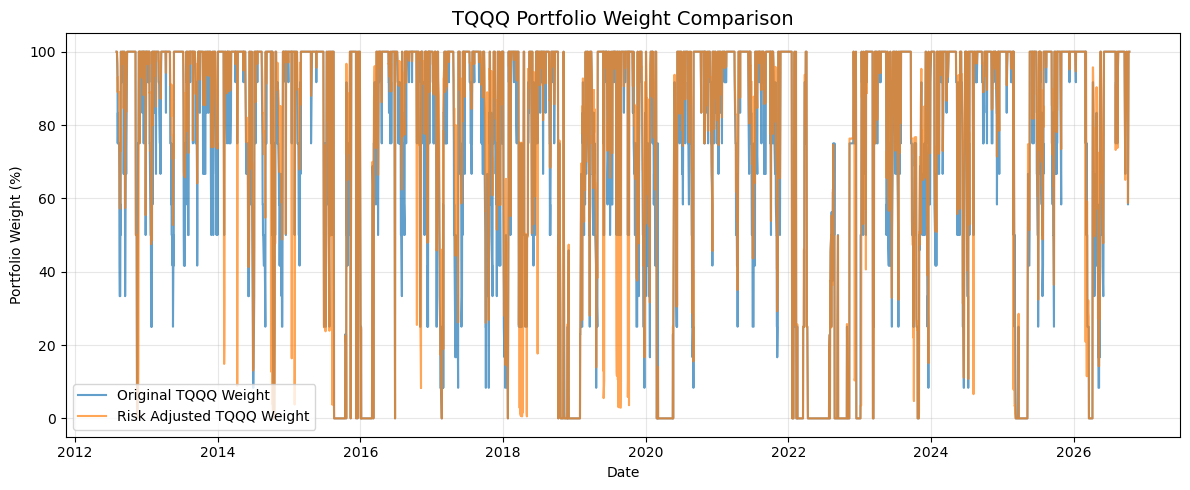

In [35]:
# ============================================================
# Step 10.4: TQQQ仓位调整对比
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    raw_weights.index,
    raw_weights["TQQQ"] * 100,
    label="Original TQQQ Weight",
    alpha=0.7
)

plt.plot(
    final_weights.index,
    final_weights["TQQQ"] * 100,
    label="Risk Adjusted TQQQ Weight",
    alpha=0.7
)

plt.title(
    "TQQQ Portfolio Weight Comparison",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Portfolio Weight (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "risk_weight_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# ============================================================
# Step 11: 波动率观察窗口稳健性测试
# ============================================================

LOOKBACKS = [30, 60, 90, 120]
ALPHA = 1.0
TRADING_DAYS = 252

lookback_results = []
lookback_weights = {}
lookback_equities = {}

# ------------------------------------------------------------
# 1. 分别测试不同的历史窗口
# ------------------------------------------------------------

for lookback in LOOKBACKS:

    print(f"正在测试 Lookback = {lookback} ...")

    # 创建每日波动率数据表
    vol_history = pd.DataFrame(
        index=raw_weights.index,
        columns=ETFS,
        dtype=float
    )

    # --------------------------------------------------------
    # 2. 计算每一天各ETF的历史波动率
    # --------------------------------------------------------

    for date in raw_weights.index:

        past_returns = (
            valid_returns
            .loc[:date, ETFS]
            .tail(lookback)
        )

        # 确保历史数据充足
        if len(past_returns) < lookback:
            continue

        vol_history.loc[date] = (
            past_returns.std()
            * np.sqrt(TRADING_DAYS)
        ).values

    # --------------------------------------------------------
    # 3. 检查波动率数据
    # --------------------------------------------------------

    assert vol_history.notna().all().all(), (
        f"Lookback={lookback} 存在缺失波动率"
    )

    assert (vol_history > 0).all().all(), (
        f"Lookback={lookback} 存在无效波动率"
    )

    # --------------------------------------------------------
    # 4. 根据波动率重新计算仓位
    # --------------------------------------------------------

    scores = raw_weights.div(
        vol_history ** ALPHA
    )

    weights = scores.div(
        scores.sum(axis=1),
        axis=0
    )

    # 确保每天仓位合计100%
    assert np.allclose(
        weights.sum(axis=1),
        1.0
    )

    # 确保没有负仓位
    assert (weights >= 0).all().all()

    # 保存每日仓位
    lookback_weights[lookback] = weights

    # --------------------------------------------------------
    # 5. 使用小组回测函数
    # --------------------------------------------------------

    equity, diag = backtest_weighted_portfolio(
        O,
        C,
        weights,
        start=IS_START
    )

    lookback_equities[lookback] = equity

    # --------------------------------------------------------
    # 6. 计算各区间绩效
    # --------------------------------------------------------

    for period, (start, end) in periods.items():

        result = metrics(
            equity,
            a=start,
            b=end
        )

        lookback_results.append({
            "Lookback": lookback,
            "Alpha": ALPHA,
            "Period": period,
            **result
        })

    print(f"Lookback = {lookback} 完成！")


# ------------------------------------------------------------
# 7. 汇总结果
# ------------------------------------------------------------

lookback_comparison = pd.DataFrame(
    lookback_results
)

print("\n========== 全部窗口测试结果 ==========")

display(
    lookback_comparison.round(4)
)


# ------------------------------------------------------------
# 8. 样本内结果
# ------------------------------------------------------------

print("\n========== IS 样本内 ==========")

display(
    lookback_comparison[
        lookback_comparison["Period"] == "IS"
    ].round(4)
)


# ------------------------------------------------------------
# 9. 样本外结果
# ------------------------------------------------------------

print("\n========== OOS 样本外 ==========")

display(
    lookback_comparison[
        lookback_comparison["Period"] == "OOS"
    ].round(4)
)


# ------------------------------------------------------------
# 10. 不包含2020年
# ------------------------------------------------------------

print("\n========== OOS ex-2020 ==========")

display(
    lookback_comparison[
        lookback_comparison["Period"] == "OOS ex-2020"
    ].round(4)
)


# ------------------------------------------------------------
# 11. 检查60日窗口是否复现原结果
# ------------------------------------------------------------

print("\n========== 60日窗口一致性检查 ==========")

same_weights = np.allclose(
    lookback_weights[60][ETFS].values,
    adjusted_weights[ETFS].values
)

print("与Step 5的仓位是否一致：", same_weights)

assert same_weights, "60日窗口未能复现之前的仓位！"

正在测试 Lookback = 30 ...
Lookback = 30 完成！
正在测试 Lookback = 60 ...
Lookback = 60 完成！
正在测试 Lookback = 90 ...
Lookback = 90 完成！
正在测试 Lookback = 120 ...
Lookback = 120 完成！

========== 全部窗口测试结果 ==========


,Lookback,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,30,1.0,IS,0.5298,0.4072,1.2496,1.8709,-0.5263,1.0067
1,30,1.0,OOS,1.0104,0.5547,1.5386,2.3942,-0.4462,2.2644
2,30,1.0,OOS ex-2020,0.6223,0.5347,1.1719,1.8147,-0.4462,1.3946
3,60,1.0,IS,0.5255,0.4081,1.2404,1.8616,-0.5278,0.9956
4,60,1.0,OOS,1.0196,0.5569,1.5428,2.4004,-0.4465,2.2836
5,60,1.0,OOS ex-2020,0.6253,0.5348,1.1754,1.8151,-0.4465,1.4004
6,90,1.0,IS,0.5283,0.4086,1.2439,1.8698,-0.5283,1.0000
7,90,1.0,OOS,1.0226,0.5570,1.5453,2.4040,-0.4463,2.2912
8,90,1.0,OOS ex-2020,0.6180,0.5353,1.1663,1.8006,-0.4463,1.3847
9,120,1.0,IS,0.5335,0.4095,1.2502,1.8849,-0.5300,1.0066



========== IS 样本内 ==========


,Lookback,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
0,30,1.0,IS,0.5298,0.4072,1.2496,1.8709,-0.5263,1.0067
3,60,1.0,IS,0.5255,0.4081,1.2404,1.8616,-0.5278,0.9956
6,90,1.0,IS,0.5283,0.4086,1.2439,1.8698,-0.5283,1.0000
9,120,1.0,IS,0.5335,0.4095,1.2502,1.8849,-0.5300,1.0066



========== OOS 样本外 ==========


,Lookback,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
1,30,1.0,OOS,1.0104,0.5547,1.5386,2.3942,-0.4462,2.2644
4,60,1.0,OOS,1.0196,0.5569,1.5428,2.4004,-0.4465,2.2836
7,90,1.0,OOS,1.0226,0.5570,1.5453,2.4040,-0.4463,2.2912
10,120,1.0,OOS,1.0249,0.5576,1.5463,2.4060,-0.4463,2.2965



========== OOS ex-2020 ==========


,Lookback,Alpha,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar
2,30,1.0,OOS ex-2020,0.6223,0.5347,1.1719,1.8147,-0.4462,1.3946
5,60,1.0,OOS ex-2020,0.6253,0.5348,1.1754,1.8151,-0.4465,1.4004
8,90,1.0,OOS ex-2020,0.6180,0.5353,1.1663,1.8006,-0.4463,1.3847
11,120,1.0,OOS ex-2020,0.6138,0.5353,1.1615,1.7917,-0.4463,1.3754



========== 60日窗口一致性检查 ==========
与Step 5的仓位是否一致： True


In [37]:
# 保存波动率窗口稳健性测试结果

lookback_output = (
    ROOT / "results/tables/risk_lookback_robustness.csv"
)

lookback_comparison.to_csv(
    lookback_output,
    index=False
)

print("已保存波动率窗口稳健性测试结果：")
print(lookback_output)

已保存波动率窗口稳健性测试结果：
/Users/zhangjiaxin/Desktop/fe5209_vol_rotation/results/tables/risk_lookback_robustness.csv
